# Week 4 - Day 3: Regression Analysis

## Objective
To measure relationships between variables using Pearson
and Spearman correlation and build a simple linear
regression model using Scikit-learn.

### Dataset
Salary Dataset with Extra Features

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
df = pd.read_csv("Salary_Dataset_with_Extra_Features.csv")

print("Dataset loaded successfully!")

print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (22770, 8)


,Rating,Company Name,Job Title,Salary,Salaries Reported,Location,Employment Status,Job Roles
0,3.8,Sasken,Android Developer,400000,3,Bangalore,Full Time,Android
1,4.5,Advanced Millennium Technologies,Android Developer,400000,3,Bangalore,Full Time,Android
2,4.0,Unacademy,Android Developer,1000000,3,Bangalore,Full Time,Android
3,3.8,SnapBizz Cloudtech,Android Developer,300000,3,Bangalore,Full Time,Android
4,4.4,Appoids Tech Solutions,Android Developer,600000,3,Bangalore,Full Time,Android


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22770 entries, 0 to 22769
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Rating             22770 non-null  float64
 1   Company Name       22769 non-null  object 
 2   Job Title          22770 non-null  object 
 3   Salary             22770 non-null  int64  
 4   Salaries Reported  22770 non-null  int64  
 5   Location           22770 non-null  object 
 6   Employment Status  22770 non-null  object 
 7   Job Roles          22770 non-null  object 
dtypes: float64(1), int64(2), object(5)
memory usage: 1.4+ MB


In [5]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
Rating               0
Company Name         1
Job Title            0
Salary               0
Salaries Reported    0
Location             0
Employment Status    0
Job Roles            0
dtype: int64


In [6]:
df.describe()

,Rating,Salary,Salaries Reported
count,22770.000000,2.277000e+04,22770.000000
mean,3.918213,6.953872e+05,1.855775
std,0.519675,8.843990e+05,6.823668
min,1.000000,2.112000e+03,1.000000
25%,3.700000,3.000000e+05,1.000000
50%,3.900000,5.000000e+05,1.000000
75%,4.200000,9.000000e+05,1.000000
max,5.000000,9.000000e+07,361.000000


In [7]:
df['Salary'] = (
    df['Salary']
    .astype(str)
    .str.replace(',', '', regex=False)
    .str.replace('₹', '', regex=False)
    .str.strip()
)

df['Salary'] = pd.to_numeric(df['Salary'], errors='coerce')

df['Rating'] = pd.to_numeric(df['Rating'], errors='coerce')

df['Salaries Reported'] = pd.to_numeric(
    df['Salaries Reported'], errors='coerce'
)

df.dropna(subset=[
    'Salary',
    'Rating',
    'Salaries Reported'
], inplace=True)

print("Data cleaning completed!")
print("Final dataset shape:", df.shape)

Data cleaning completed!
Final dataset shape: (22770, 8)


In [8]:
numeric_df = df.select_dtypes(include=np.number)

pearson_corr = numeric_df.corr(method='pearson')

print("Pearson Correlation Matrix:")
display(pearson_corr)

Pearson Correlation Matrix:


,Rating,Salary,Salaries Reported
Rating,1.000000,0.025476,-0.011690
Salary,0.025476,1.000000,0.004481
Salaries Reported,-0.011690,0.004481,1.000000


In [9]:
spearman_corr = numeric_df.corr(method='spearman')

print("Spearman Correlation Matrix:")
display(spearman_corr)

Spearman Correlation Matrix:


,Rating,Salary,Salaries Reported
Rating,1.000000,0.020317,0.003197
Salary,0.020317,1.000000,-0.008075
Salaries Reported,0.003197,-0.008075,1.000000


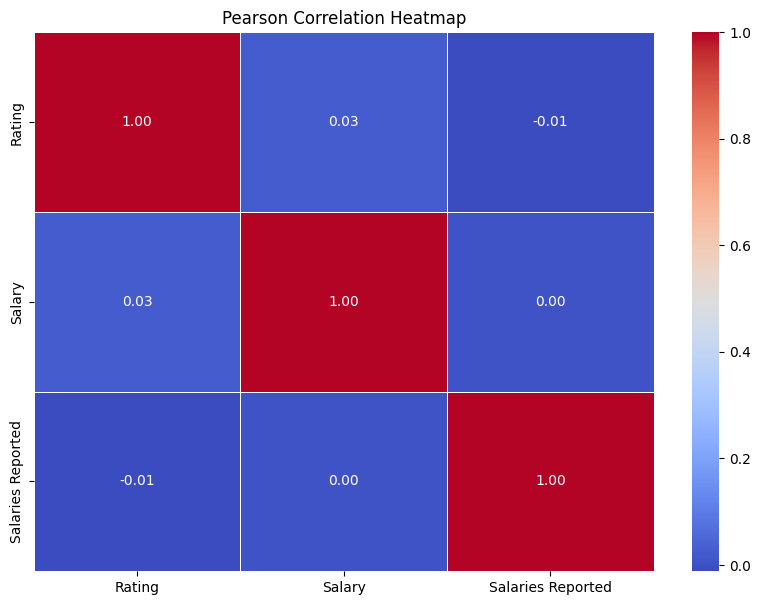

In [10]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    pearson_corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title("Pearson Correlation Heatmap")

plt.show()

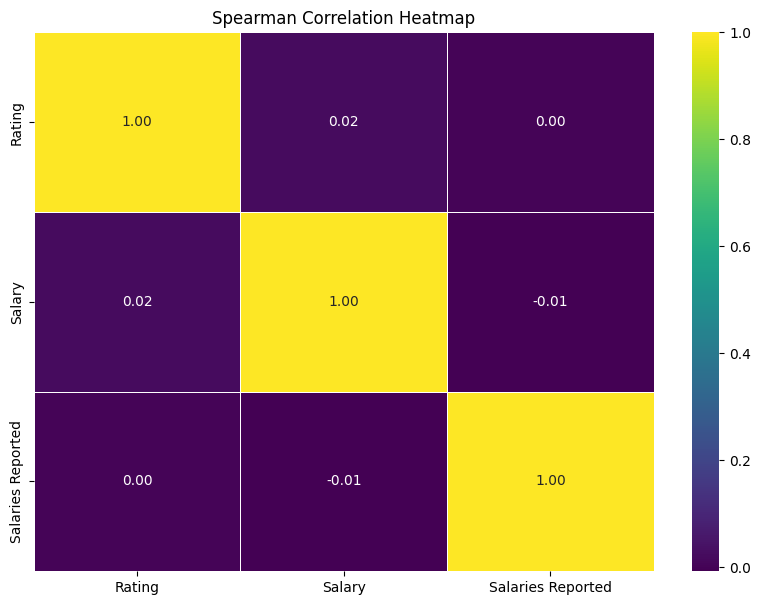

In [11]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    spearman_corr,
    annot=True,
    cmap='viridis',
    fmt='.2f',
    linewidths=0.5
)

plt.title("Spearman Correlation Heatmap")

plt.show()

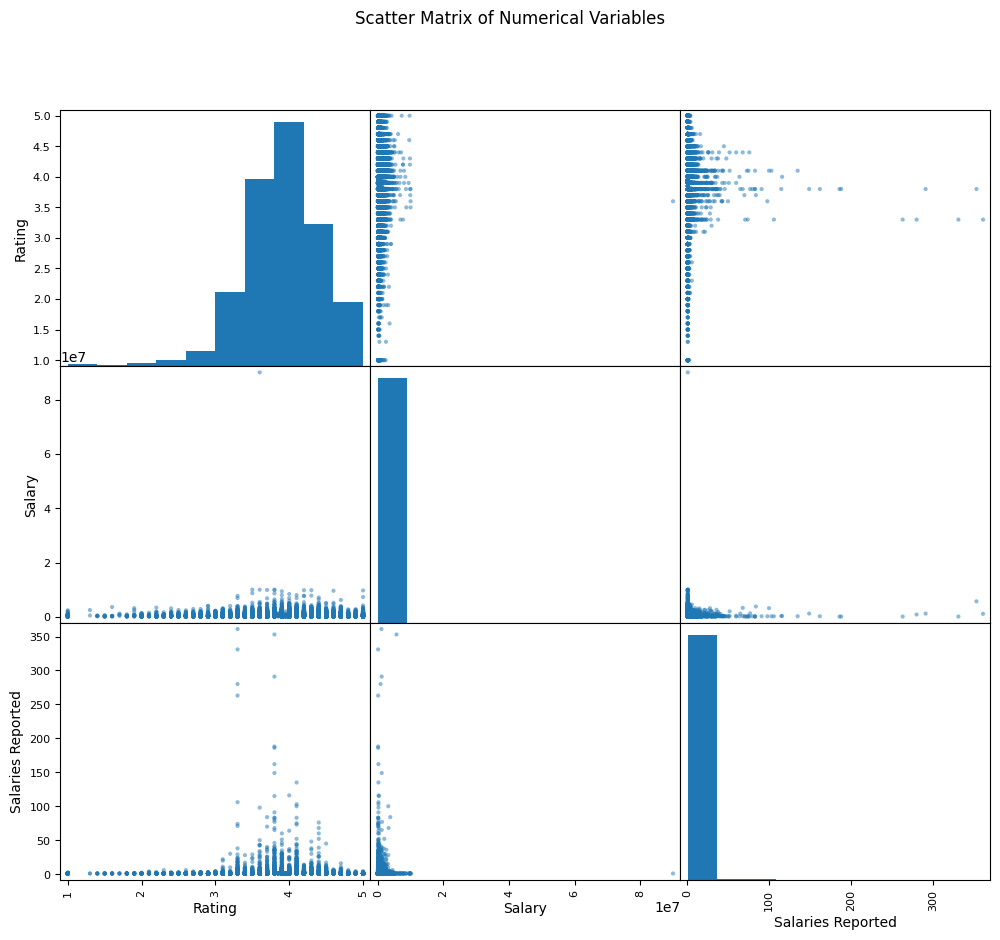

In [12]:
from pandas.plotting import scatter_matrix

scatter_matrix(
    numeric_df,
    figsize=(12, 10),
    diagonal='hist',
    alpha=0.5
)

plt.suptitle("Scatter Matrix of Numerical Variables")

plt.show()

In [13]:
X = df[['Rating']]

y = df['Salary']

print("Independent Variable: Rating")
print("Dependent Variable: Salary")

Independent Variable: Rating
Dependent Variable: Salary


In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 18216
Testing records: 4554


In [15]:
model = LinearRegression()

model.fit(X_train, y_train)

print("Linear Regression Model Trained Successfully!")

Linear Regression Model Trained Successfully!


In [16]:
y_pred = model.predict(X_test)

print("Actual Salaries:")
print(y_test.head().values)

print("\nPredicted Salaries:")
print(y_pred[:5])

Actual Salaries:
[800000 100000 400000 300000 500000]

Predicted Salaries:
[688138.99246601 700255.44493747 676022.53999454 696216.62744698
 708333.07991844]


In [17]:
print("Slope:", model.coef_[0])

print("Intercept:", model.intercept_)

print(
    f"Regression Equation: Salary = "
    f"{model.coef_[0]:.2f} * Rating + "
    f"{model.intercept_:.2f}"
)

Slope: 40388.17490487151
Intercept: 538702.7453179804
Regression Equation: Salary = 40388.17 * Rating + 538702.75


In [18]:
r2 = r2_score(y_test, y_pred)

mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("MODEL EVALUATION")
print("--------------------------")

print("R2 Score:", r2)

print("MAE:", mae)

print("RMSE:", rmse)

MODEL EVALUATION
--------------------------
R2 Score: 0.0017307715376226884
MAE: 431562.09030133236
RMSE: 636229.9408420698


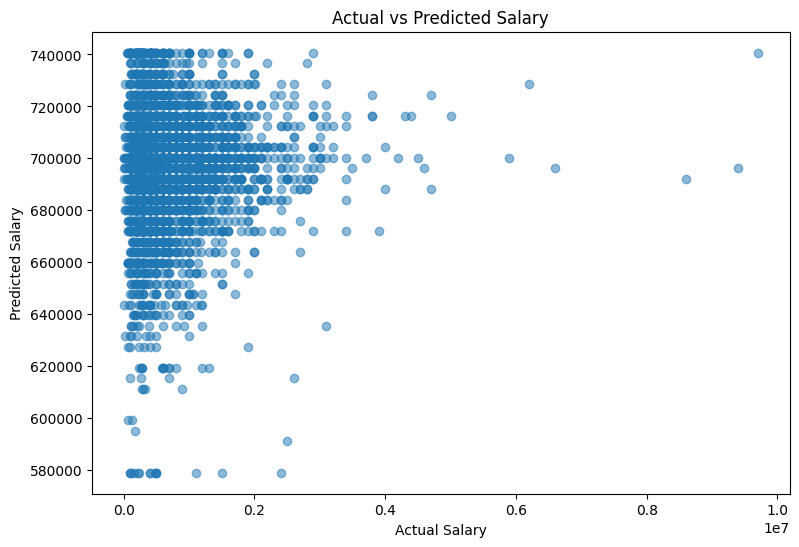

In [19]:
plt.figure(figsize=(9, 6))

plt.scatter(y_test, y_pred, alpha=0.5)

plt.xlabel("Actual Salary")

plt.ylabel("Predicted Salary")

plt.title("Actual vs Predicted Salary")

plt.show()

In [20]:
residuals = y_test - y_pred

print(residuals.head())

17397    111861.007534
18549   -600255.444937
8565    -276022.539995
8639    -396216.627447
13354   -208333.079918
Name: Salary, dtype: float64


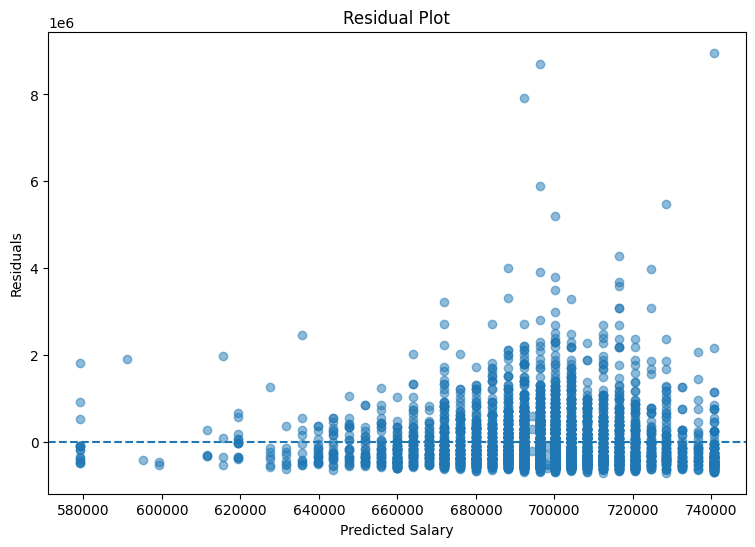

In [21]:
plt.figure(figsize=(9, 6))

plt.scatter(y_pred, residuals, alpha=0.5)

plt.axhline(y=0, linestyle='--')

plt.xlabel("Predicted Salary")

plt.ylabel("Residuals")

plt.title("Residual Plot")

plt.show()

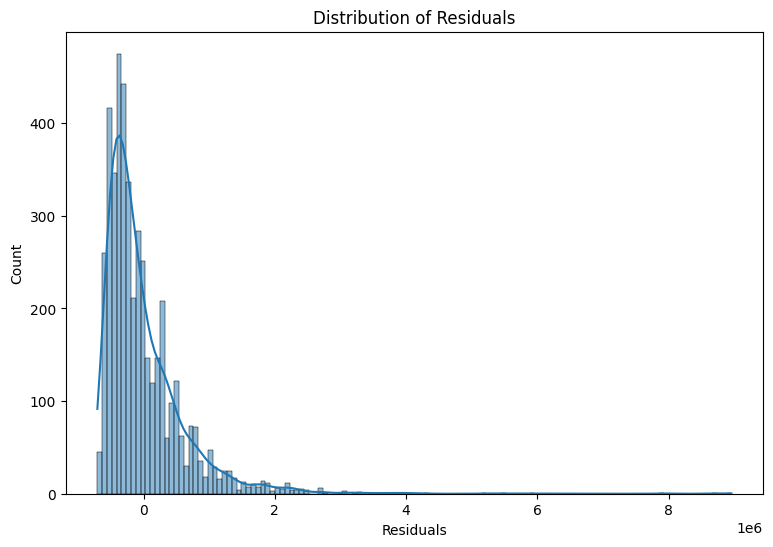

In [22]:
plt.figure(figsize=(9, 6))

sns.histplot(residuals, kde=True)

plt.title("Distribution of Residuals")

plt.xlabel("Residuals")

plt.show()

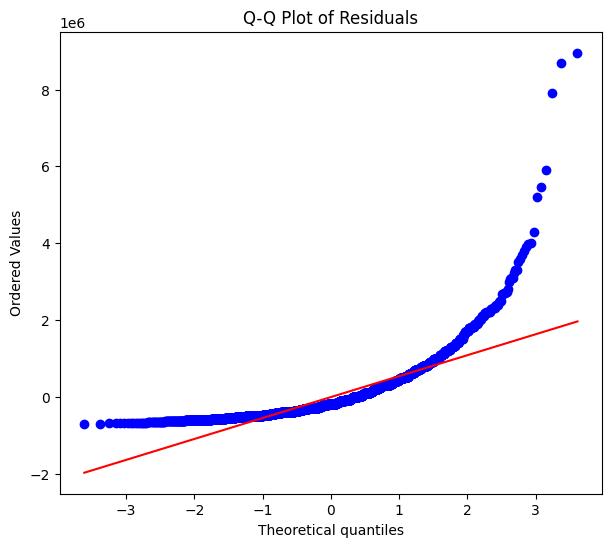

In [23]:
import scipy.stats as stats

plt.figure(figsize=(7, 6))

stats.probplot(residuals, dist="norm", plot=plt)

plt.title("Q-Q Plot of Residuals")

plt.show()

## Business Insights

1. Pearson correlation was used to identify
linear relationships between numerical variables.

2. Spearman correlation was used to identify
monotonic relationships between variables.

3. Correlation heatmaps helped identify
positive and negative relationships.

4. A simple linear regression model was developed
to predict salary using company rating.

5. R², MAE and RMSE were used to evaluate
the model performance.

6. Residual analysis was performed to examine
the regression model assumptions.

## Conclusion

Correlation analysis and linear regression
helped understand relationships between company
ratings and reported salaries.

The analysis also demonstrated the importance
of model evaluation and residual diagnostics.